<a href="https://colab.research.google.com/github/diakiteamad/analyse-titanic/blob/main/analyse_titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analyse de la survie des passagers du Titanic

**Question** : quels facteurs ont le plus influencé les chances de survie des passagers ?

**Données** : jeu de données public « Titanic » (bibliothèque seaborn), 891 passagers.

**Outils** : Python, Pandas, NumPy, Matplotlib.

## Étape 1 — Chargement et nettoyage

Choix de nettoyage :
- les lignes identiques sont **conservées** : sans nom ni identifiant, elles correspondent à des passagers différents aux caractéristiques identiques ;
- une colonne `age_manquant` garde la trace des âges inconnus, avant leur estimation ;
- les âges manquants sont remplacés par la **médiane par classe et par sexe**, plus réaliste qu'une médiane unique ;
- la colonne `deck`, presque vide, est supprimée.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
titanic = pd.read_csv(url)

# Trace des âges inconnus, avant leur estimation
titanic["age_manquant"] = titanic["age"].isna()

# Âges manquants : médiane par classe et par sexe
titanic["age"] = titanic["age"].fillna(
    titanic.groupby(["pclass", "sex"])["age"].transform("median")
)

# Colonne presque vide
titanic = titanic.drop(columns="deck")

print(f"Nombre de passagers : {len(titanic)}")
print(f"Âges estimés : {titanic['age_manquant'].sum()}")
titanic.head()

Nombre de passagers : 891
Âges estimés : 177


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,age_manquant
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,False


## Étape 2 — Le taux de survie global

In [5]:
print(f"Taux de survie global : {100 * titanic['survived'].mean():.2f} %")

Taux de survie global : 38.38 %


## Étape 3 — Facteur par facteur

Pour chaque facteur : le taux de survie (en %) et l'effectif de chaque groupe, pour repérer les taux calculés sur trop peu de passagers.

In [6]:
def taux_et_effectifs(df, colonne):
    return pd.DataFrame({
        "taux_survie_%": (df.groupby(colonne)["survived"].mean() * 100).round(1),
        "effectif": df[colonne].value_counts(),
    })

print("Par sexe :")
print(taux_et_effectifs(titanic, "sex"))

Par sexe :
        taux_survie_%  effectif
sex                            
female           74.2       314
male             18.9       577


In [7]:
print("Par classe :")
print(taux_et_effectifs(titanic, "pclass"))

Par classe :
        taux_survie_%  effectif
pclass                         
1                63.0       216
2                47.3       184
3                24.2       491


In [8]:
titanic["tranche_age"] = pd.cut(
    titanic["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Enfant", "Adolescent", "Adulte", "Âge mûr", "Senior"]
)

print("Par tranche d'âge :")
print(taux_et_effectifs(titanic, "tranche_age"))

Par tranche d'âge :
             taux_survie_%  effectif
tranche_age                         
Enfant                58.0        69
Adolescent            42.9        70
Adulte                36.0       602
Âge mûr               39.1       128
Senior                22.7        22


/tmp/ipykernel_1058/1748002363.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "taux_survie_%": (df.groupby(colonne)["survived"].mean() * 100).round(1),


In [9]:
print("Par port d'embarquement :")
print(taux_et_effectifs(titanic, "embark_town"))

Par port d'embarquement :
             taux_survie_%  effectif
embark_town                         
Cherbourg             55.4       168
Queenstown            39.0        77
Southampton           33.7       644


## Étape 4 — Croiser les facteurs

In [10]:
print("Taux de survie (%) par sexe et par classe :")
print((titanic.pivot_table(values="survived", index="sex", columns="pclass", aggfunc="mean") * 100).round(1))

Taux de survie (%) par sexe et par classe :
pclass     1     2     3
sex                     
female  96.8  92.1  50.0
male    36.9  15.7  13.5


L'effet du sexe est fort dans toutes les classes, mais il n'a pas la même forme :
- pour les femmes, la rupture se situe entre la 2e et la 3e classe ;
- pour les hommes, elle se situe entre la 1re et la 2e classe.

Le sexe et la classe **interagissent**.

In [11]:
print("Répartition des classes par port d'embarquement (part de chaque classe parmi les passagers du port) :")
print(pd.crosstab(titanic["embark_town"], titanic["pclass"], normalize="index").round(2))

Répartition des classes par port d'embarquement (part de chaque classe parmi les passagers du port) :
pclass          1     2     3
embark_town                  
Cherbourg    0.51  0.10  0.39
Queenstown   0.03  0.04  0.94
Southampton  0.20  0.25  0.55


Environ la moitié des passagers embarqués à Cherbourg voyageaient en 1re classe, contre moins d'un quart à Southampton. La classe est une **variable de confusion** : elle explique probablement le meilleur taux de survie de Cherbourg.

## Étape 5 — Visualisations

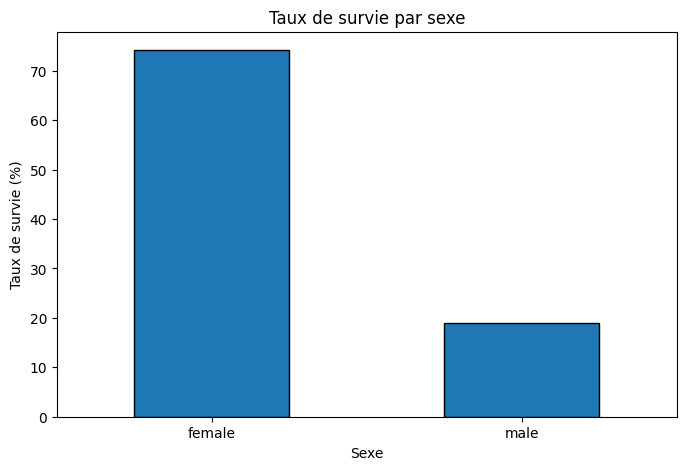

In [12]:
taux_survie = titanic.groupby("sex")["survived"].mean() * 100

taux_survie.plot(kind="bar", figsize=(8, 5), edgecolor="black")
plt.xlabel("Sexe")
plt.ylabel("Taux de survie (%)")
plt.title("Taux de survie par sexe")
plt.xticks(rotation=0)
plt.show()

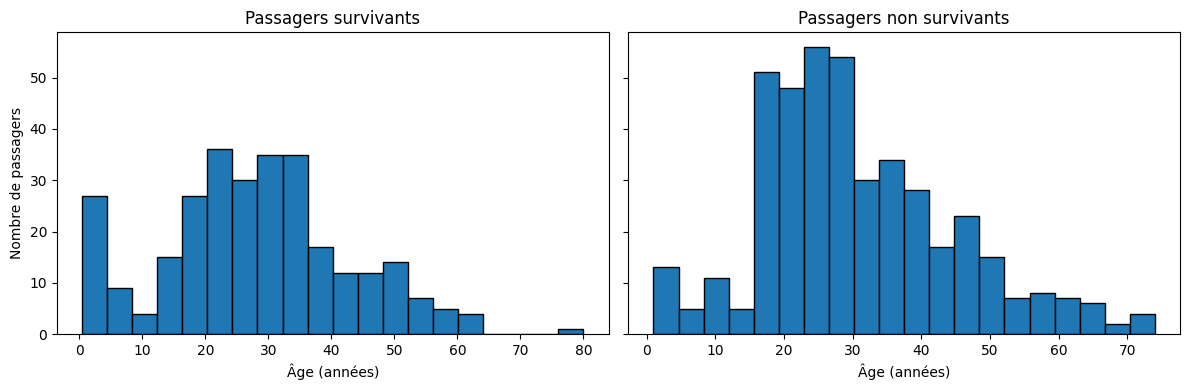

In [13]:
# Seuls les âges réellement connus, pour éviter les pics créés par l'estimation
ages_connus = titanic[~titanic["age_manquant"]]
survivants = ages_connus.loc[ages_connus["survived"] == 1, "age"]
non_survivants = ages_connus.loc[ages_connus["survived"] == 0, "age"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(survivants, bins=20, edgecolor="black")
axes[0].set_title("Passagers survivants")
axes[0].set_xlabel("Âge (années)")
axes[0].set_ylabel("Nombre de passagers")

axes[1].hist(non_survivants, bins=20, edgecolor="black")
axes[1].set_title("Passagers non survivants")
axes[1].set_xlabel("Âge (années)")

plt.tight_layout()
plt.show()

## Étape 6 — Conclusion

Sur les 891 passagers, 38,4 % ont survécu. Le sexe est le facteur le plus déterminant : 74,2 % des femmes ont survécu, contre 18,9 % des hommes. La classe vient ensuite, avec un taux de survie de 63,0 % en 1re classe, 47,3 % en 2e et 24,2 % en 3e.

Les deux facteurs interagissent : les femmes de 1re et 2e classe ont presque toutes survécu (plus de 90 %), contre la moitié seulement en 3e classe. Les enfants ont eu un taux de survie supérieur à la moyenne, les seniors un taux plus faible.

Le meilleur taux observé à Cherbourg s'explique probablement par la part élevée de passagers de 1re classe parmi ceux qui y ont embarqué : le port ne semble pas être un facteur en soi.

**Limites** : certains groupes comptent peu de passagers (enfants, seniors), ce qui rend leurs taux fragiles. Les âges manquants ont été estimés, ce qui peut légèrement fausser l'analyse par tranche d'âge.